# Neural Networks and Deep Learning — Lecture 1: Deep learning for business: from linear models to the perceptron and the MLP
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L1_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


On macOS, if the kernel stops when XGBoost and PyTorch run in the same session, start Jupyter with `OMP_NUM_THREADS=1 jupyter lab` (the two libraries ship different OpenMP runtimes). Colab is not affected.

In [3]:
import xgboost as xgb
import torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold
torch.set_num_threads(1)
NUM = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']

def encode_hmeq(tr, others):
    """median fill + missing indicators + one-hot, fitted on the training part only (no leakage)"""
    med = tr[NUM].median()
    def f(d):
        x = pd.DataFrame(index=d.index)
        for c in NUM:
            x[c] = d[c].fillna(med[c]); x['miss_' + c] = d[c].isna().astype(float)
        for c, lv in (('REASON', ['DebtCon', 'HomeImp']), ('JOB', ['Mgr', 'Office', 'Other', 'ProfExe', 'Sales', 'Self'])):
            for v in lv:
                x[f'{c}_{v}'] = (d[c] == v).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others], list(xtr.columns)

def mlp(d, hidden=(64, 64), act=nn.ReLU):
    layers, k = [], d
    for h in hidden:
        layers += [nn.Linear(k, h), act()]; k = h
    return nn.Sequential(*layers, nn.Linear(k, 1))

def train_mlp(Xtr, ytr, Xva, yva, hidden=(64, 64), lr=1e-3, epochs=300, bs=128, patience=25, seed=0):
    """Adam on mini-batches; keeps the weights of the best validation epoch"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = mlp(Xtr.shape[1], hidden); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv))
        if vl < best - 1e-5:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state); m.eval()
    return m

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

## §1 The data: default rates by applicant group

1000 applicants, default rate %: 30.0
checking_status
A11    49.3
A12    39.0
A13    22.2
A14    11.7
Name: default, dtype: float64
0          14.0
1          33.9
2          44.8
3+         67.3
missing    12.4
Name: BAD, dtype: float64


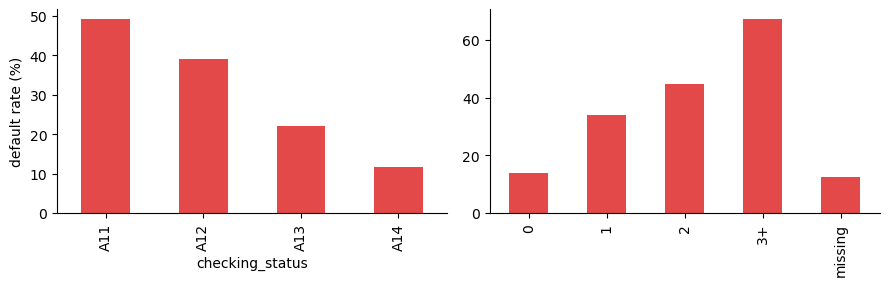

In [4]:
g = pd.read_csv(DATA + 'german_credit.csv')
print(len(g), 'applicants, default rate %:', round(100 * g['default'].mean(), 1))
print((100 * g.groupby('checking_status')['default'].mean()).round(1))
hm = pd.read_csv(DATA + 'hmeq.csv')
d = hm['DELINQ']; cat = np.where(d.isna(), 'missing', np.where(d >= 3, '3+', d.fillna(0).astype(int).astype(str)))
print((100 * hm.groupby(cat)['BAD'].mean()).round(1))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
(100 * g.groupby('checking_status')['default'].mean()).plot.bar(ax=ax[0], color='#e34948'); ax[0].set_ylabel('default rate (%)')
(100 * hm.groupby(cat)['BAD'].mean()).plot.bar(ax=ax[1], color='#e34948'); plt.tight_layout(); plt.show()

## §2 Logistic regression as one neuron (HMEQ)

In [5]:
h = pd.read_csv(DATA + 'hmeq.csv'); yh = h.pop('BAD').values.astype(int)
idx = np.arange(len(h))
i_tr, i_te = train_test_split(idx, test_size=0.2, stratify=yh, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, stratify=yh[i_tr], random_state=SEED)
(Xtr, Xva, Xte), cols = encode_hmeq(h.iloc[i_tr], [h.iloc[i_va], h.iloc[i_te]])
ytr, yva, yte = yh[i_tr], yh[i_va], yh[i_te]
print('train / validation / test:', len(i_tr), len(i_va), len(i_te), '| inputs d =', Xtr.shape[1])

train / validation / test: 3576 1192 1192 | inputs d = 28


In [6]:
import statsmodels.api as sm
base = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'miss_DEBTINC']
ci = [cols.index(c) for c in base]
lm = sm.Logit(ytr, sm.add_constant(Xtr[:, ci].astype(float))).fit(disp=0)
print(pd.DataFrame({'coef': lm.params[1:], 'odds ratio': np.exp(lm.params[1:])}, index=base).round(3))
print('McFadden pseudo-R2:', round(lm.prsquared, 3))
print('default rate when DEBTINC is missing / present (%):',
      round(100 * yh[h['DEBTINC'].isna().values].mean(), 1), round(100 * yh[h['DEBTINC'].notna().values].mean(), 1))

               coef  odds ratio
LOAN         -0.076       0.927
MORTDUE      -0.040       0.961
VALUE         0.226       1.253
YOJ          -0.056       0.946
DEROG         0.452       1.571
DELINQ        0.774       2.169
CLAGE        -0.424       0.655
NINQ          0.209       1.232
CLNO         -0.221       0.802
DEBTINC       0.528       1.696
miss_DEBTINC  1.062       2.892
McFadden pseudo-R2: 0.374
default rate when DEBTINC is missing / present (%): 62.0 8.6


Forward pass of one real test applicant: the score is the sum of the contributions $w_jx_j$.

In [7]:
j = next(k for k in np.where(yte == 1)[0] if h.iloc[i_te[k]][base[:-1]].notna().all())
x = Xte[j, ci].astype(float); contrib = lm.params[1:] * x
z = lm.params[0] + contrib.sum()
print(pd.Series(contrib, index=base).sort_values(key=abs, ascending=False).round(2).head(3))
print('score z =', round(z, 2), ' PD =', round(100 / (1 + np.exp(-z)), 1), '%')

DELINQ          1.13
CLNO           -0.62
miss_DEBTINC   -0.54
dtype: float64
score z = -1.71  PD = 15.3 %


## §3 Perceptron convergence on real loan data

perceptron error % min / max: 13.2 23.4
logistic regression error %: 11.7


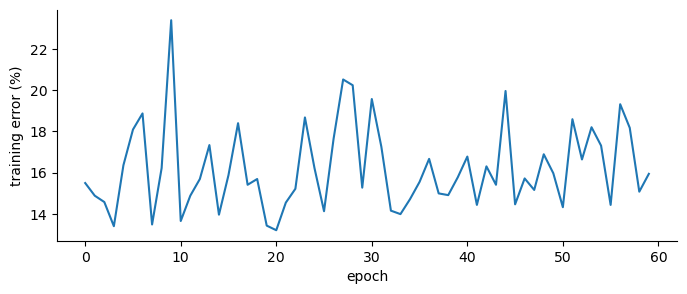

In [8]:
rng = np.random.default_rng(SEED); s = 2 * ytr - 1; X = Xtr.astype(float)
w, b, err = np.zeros(X.shape[1]), 0.0, []
for ep in range(60):
    for i in rng.permutation(len(X)):
        if s[i] * (X[i] @ w + b) <= 0:
            w += s[i] * X[i]; b += s[i]
    err.append(np.mean(np.sign(X @ w + b + 1e-12) != s))
lr = LogisticRegression(C=1e6, max_iter=5000).fit(Xtr, ytr)
print('perceptron error % min / max:', round(100 * min(err), 1), round(100 * max(err), 1))
print('logistic regression error %:', round(100 * np.mean((lr.predict_proba(Xtr)[:, 1] > 0.5) != ytr), 1))
plt.figure(figsize=(8, 3)); plt.plot(100 * np.array(err)); plt.ylabel('training error (%)'); plt.xlabel('epoch'); plt.show()

## §4 The MLP: universal approximation on California housing

In [9]:
ca = pd.read_csv(DATA + 'california_housing.csv')
x1, y1 = ca['Latitude'].values.astype(np.float32), ca['MedHouseVal_100k_usd'].values.astype(np.float32)
keep = y1 < 5.0; x1, y1 = x1[keep], y1[keep]           # drop the block groups at the source cap
a, bb = train_test_split(np.arange(len(x1)), test_size=0.25, random_state=SEED)
mx, sx = x1[a].mean(), x1[a].std()
for H in (1, 3, 50):
    torch.manual_seed(SEED + H); m = mlp(1, (H,), nn.Sigmoid); opt = torch.optim.Adam(m.parameters(), lr=0.02)
    Xa, Ya = torch.tensor((x1[a, None] - mx) / sx), torch.tensor(y1[a, None])
    for it in range(4000):
        opt.zero_grad(); nn.MSELoss()(m(Xa), Ya).backward(); opt.step()
    with torch.no_grad():
        mse = float(nn.MSELoss()(m(torch.tensor((x1[bb, None] - mx) / sx)), torch.tensor(y1[bb, None])))
    print('H =', H, ' held-out MSE =', round(mse, 3))
bl = np.polyfit(x1[a], y1[a], 1); print('linear held-out MSE =', round(np.mean((np.polyval(bl, x1[bb]) - y1[bb]) ** 2), 3))

H = 1  held-out MSE = 0.855


H = 3  held-out MSE = 0.757


H = 50  held-out MSE = 0.731
linear held-out MSE = 0.896


§ Experiment yourself: replace the sigmoid by `nn.ReLU` and compare the shapes of the fitted curves.

## §5 Case study: logistic regression, MLP and XGBoost on HMEQ

In [10]:
p_lr = lr.predict_proba(Xte)[:, 1]
xg = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                       eval_metric='logloss', early_stopping_rounds=50, random_state=SEED, n_jobs=1)
xg.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False); p_xg = xg.predict_proba(Xte)[:, 1]
aucs = [roc_auc_score(yte, proba(train_mlp(Xtr, ytr, Xva, yva, seed=s), Xte)) for s in range(5)]
print('test AUC  logistic', round(roc_auc_score(yte, p_lr), 3), '| XGBoost', round(roc_auc_score(yte, p_xg), 3),
      '| MLP 64-64 mean of 5 seeds', round(np.mean(aucs), 3), '(sd', round(np.std(aucs, ddof=1), 3), ')')

test AUC  logistic 0.92 | XGBoost 0.961 | MLP 64-64 mean of 5 seeds 0.945 (sd 0.004 )


AUC gain MLP - logistic: 0.023  95% bootstrap interval: [0.008 0.037]
logistic Brier 0.0742  defaults caught at 10% FPR: 83.2
MLP Brier 0.0625  defaults caught at 10% FPR: 85.3
XGBoost Brier 0.0549  defaults caught at 10% FPR: 90.8


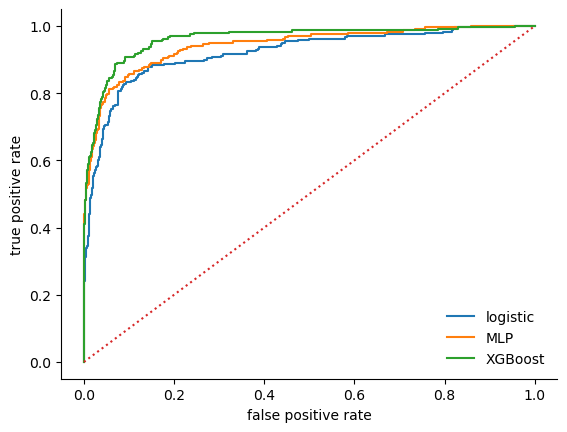

In [11]:
m0 = train_mlp(Xtr, ytr, Xva, yva, seed=0); p_ml = proba(m0, Xte)
rng = np.random.default_rng(SEED); diffs = []
for _ in range(2000):
    b = rng.integers(0, len(yte), len(yte))
    if yte[b].min() == yte[b].max():
        continue
    diffs.append(roc_auc_score(yte[b], p_ml[b]) - roc_auc_score(yte[b], p_lr[b]))
print('AUC gain MLP - logistic:', round(roc_auc_score(yte, p_ml) - roc_auc_score(yte, p_lr), 3),
      ' 95% bootstrap interval:', np.round(np.percentile(diffs, [2.5, 97.5]), 3))
for nm, p in (('logistic', p_lr), ('MLP', p_ml), ('XGBoost', p_xg)):
    fpr, tpr, _ = roc_curve(yte, p); plt.plot(fpr, tpr, label=nm)
    print(nm, 'Brier', round(brier_score_loss(yte, p), 4), ' defaults caught at 10% FPR:', round(100 * np.interp(0.1, fpr, tpr), 1))
plt.plot([0, 1], [0, 1], ':'); plt.xlabel('false positive rate'); plt.ylabel('true positive rate'); plt.legend(); plt.show()

§ Experiment yourself: vary the width of one hidden layer, `hidden=(H,)` with H from 1 to 256, and plot the test AUC against H (the slide uses 5 seeds per width).

## §6 German credit: cross-validation, a corrected t-test and the cost-optimal cut-off

In [12]:
from scipy import stats
yg = g['default'].values; Xg = g.drop(columns='default')
def enc(tr, others):
    cat = [c for c in tr.columns if tr[c].dtype == object]; num = [c for c in tr.columns if c not in cat]
    lv = {c: sorted(tr[c].unique()) for c in cat}
    f = lambda d: pd.concat([d[num].astype(float)] + [(d[c] == v).astype(float).rename(f'{c}_{v}') for c in cat for v in lv[c][1:]], axis=1)
    xt = f(tr); mu, sd = xt.mean(), xt.std().replace(0, 1)
    return [((xt - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others]
A = {'logit': [], 'mlp': []}; oof = {'logit': np.zeros(len(yg)), 'mlp': np.zeros(len(yg))}
for rep in range(5):
    for f, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED + rep).split(Xg, yg)):
        a_tr, a_va = train_test_split(a, test_size=0.2, stratify=yg[a], random_state=SEED + rep)
        xa, xv, xb = enc(Xg.iloc[a_tr], [Xg.iloc[a_va], Xg.iloc[b]])
        pl = LogisticRegression(C=1.0, max_iter=5000).fit(xa, yg[a_tr]).predict_proba(xb)[:, 1]
        pm = proba(train_mlp(xa, yg[a_tr], xv, yg[a_va], seed=rep * 10 + f, bs=64), xb)
        A['logit'].append(roc_auc_score(yg[b], pl)); A['mlp'].append(roc_auc_score(yg[b], pm))
        if rep == 0:
            oof['logit'][b], oof['mlp'][b] = pl, pm
d = np.array(A['mlp']) - np.array(A['logit']); J = len(d)
t = d.mean() / np.sqrt((1 / J + 0.25) * d.var(ddof=1))      # Nadeau-Bengio correction, n_test/n_train = 1/4
print('mean AUC logistic', round(np.mean(A['logit']), 3), '| MLP', round(np.mean(A['mlp']), 3))
print('corrected t =', round(t, 2), ' p =', round(2 * stats.t.sf(abs(t), J - 1), 3))

mean AUC logistic 0.777 | MLP 0.766
corrected t = -0.93  p = 0.362


In [13]:
cost = lambda p, thr: (5 * np.sum((p < thr) & (yg == 1)) + 1 * np.sum((p >= thr) & (yg == 0))) / len(yg)
for k in ('logit', 'mlp'):
    print(k, ' cost per applicant at 1/6:', round(cost(oof[k], 1 / 6), 3), ' at 1/2:', round(cost(oof[k], 0.5), 3))
print('accept everyone:', round(5 * yg.mean(), 2))

logit  cost per applicant at 1/6: 0.554  at 1/2: 0.87
mlp  cost per applicant at 1/6: 0.568  at 1/2: 1.13
accept everyone: 1.5


## §7 A minimal MLP in PyTorch

In [14]:
model = nn.Sequential(nn.Linear(Xtr.shape[1], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
print(model)
print('parameters:', sum(p.numel() for p in model.parameters()), '(logistic regression:', Xtr.shape[1] + 1, ')')

Sequential(
  (0): Linear(in_features=28, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 6081 (logistic regression: 29 )
